# Optimización de Portafolio ALM — Markowitz Multiperiodo

**Asset-Liability Management (ALM)** para cubrir un crédito en UVR a 120 meses.

## Idea general
Partimos de un capital inicial $C_0$ que debe invertirse en una cartera de activos
(Bono corporativo, Fondo conservador, ETF) de forma que, mes a mes, el portafolio
genere rentabilidad suficiente para pagar el flujo del pasivo $L_t$ (cuotas del crédito
en pesos) y, al final de los 120 meses, quede el mayor capital residual posible.

En cada periodo resolvemos un problema **media-varianza de Markowitz**:

$$\max_{w}\; w^\top \mu \quad \text{s.a.}\quad \sqrt{w^\top \Sigma\, w} \le \sigma_{\max},\;\; \mathbf{1}^\top w = 1,\;\; w \ge 0,\;\; w_{Fondo}+w_{ETF}\ge \beta$$

## Esquema multiperiodo (reglas de liquidez)

| Periodo | Meses     | Activos permitidos |
|---------|-----------|--------------------|
| 1       | 1 – 36    | Bono + Fondo + ETF |
| 2       | 37 – 72   | Bono + Fondo + ETF |
| 3       | 73 – 108  | Bono + Fondo + ETF |
| 4       | 109 – 120 | Solo Fondo + ETF   |

El bono corporativo solo se puede comprar/renovar cada 36 meses (vence a 3 años). Al
cierre de los meses 36, 72 y 108 el bono vence, se liquida y el capital residual del
tramo se **reoptimiza** para el periodo siguiente. El Fondo (liquidez mensual) y el ETF
(liquidez diaria) se rebalancean mensualmente; en este modelo fijamos los pesos al
inicio de cada periodo.

## 1. Importes y utilidades

Usamos `cvxpy` si está disponible (formulación convexa limpia); si no, hacemos
*fallback* a `scipy.optimize.minimize` con restricciones.

In [99]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Intentamos cvxpy; si no está, usaremos scipy como respaldo
try:
    import cvxpy as cp
    USAR_CVXPY = True
except ImportError:
    USAR_CVXPY = False

from scipy.optimize import minimize

print('Optimizador:', 'cvxpy' if USAR_CVXPY else 'scipy.optimize (fallback)')

Optimizador: scipy.optimize (fallback)


## 2. Parámetros del problema

- `C0`: capital inicial.
- `SIGMA_MAX_ANUAL`: tope de riesgo (desviación estándar) anual = 8 %.
- `BETA_LIQUIDEZ`: liquidez mínima $w_{Fondo}+w_{ETF}\ge 0.30$.
- `ARCHIVO_FLUJO`: serie $L_t$ del pasivo. **Modificable** para cualquier CSV de
  `flujosPronosticados/` (arima, mbg, Sarimax). Empezamos con MBG.

In [100]:
# --- Parámetros financieros ---
C0 = 760_000_000.0            # Capital inicial (COP)
SIGMA_MAX_ANUAL = 0.08        # Riesgo máximo anual (8%)
BETA_LIQUIDEZ = 0.30          # w_Fondo + w_ETF >= 0.30

# Conversión coherente de riesgo anual -> mensual.
# La varianza escala linealmente con el tiempo (retornos i.i.d.):  sigma_anual^2 = 12 * sigma_mensual^2
# => sigma_mensual = sigma_anual / sqrt(12)
SIGMA_MAX_MENSUAL = SIGMA_MAX_ANUAL / np.sqrt(12)

# --- Archivo del pasivo (intercambiable) ---
# Opciones: 'flujo_pronostico_uvr_mbg.csv', 'flujo_pronostico_uvr_arima.csv', 'flujo_pronostico_uvr_Sarimax.csv'
CARPETA_FLUJOS = '../flujosPronosticados'
ARCHIVO_FLUJO = 'flujo_pronostico_uvr_mbg.csv'

print(f'Capital inicial C0      : {C0:,.0f} COP')
print(f'Sigma max anual         : {SIGMA_MAX_ANUAL:.2%}')
print(f'Sigma max mensual       : {SIGMA_MAX_MENSUAL:.4%}')
print(f'Liquidez minima (beta)  : {BETA_LIQUIDEZ:.0%}')

Capital inicial C0      : 760,000,000 COP
Sigma max anual         : 8.00%
Sigma max mensual       : 2.3094%
Liquidez minima (beta)  : 30%


## 3. Carga de datos: μ, Σ y la serie del pasivo $L_t$

- `mu_activos.csv`: retornos esperados mensual y anual por activo.
- `Sigma_mensual.csv`: matriz de covarianzas **mensuales** (3×3).
- El flujo $L_t$ trae `periodo` (1..120) y `Lt` (pesos a pagar ese mes).

In [101]:
import os

# --- mu mensual por activo ---
mu_df = pd.read_csv(os.path.join('../pronosticosActivos', 'mu_activos.csv'), index_col='Activo')
ACTIVOS = list(mu_df.index)                 # ['Bono', 'Fondo', 'ETF']
mu_mensual = mu_df['mu_mensual']            # Serie indexada por activo

# --- Matriz de covarianzas mensuales ---
Sigma_df = pd.read_csv(os.path.join('../pronosticosActivos', 'Sigma_mensual.csv'), index_col=0)
Sigma_df = Sigma_df.loc[ACTIVOS, ACTIVOS]  # Reordena para alinear con ACTIVOS

# --- Serie del pasivo L_t ---
flujo_df = pd.read_csv(os.path.join(CARPETA_FLUJOS, ARCHIVO_FLUJO))
flujo_df = flujo_df.sort_values('periodo').reset_index(drop=True)
Lt = flujo_df['Lt'].to_numpy()             # L_t para t = 1..120
N_MESES = len(Lt)

print('Activos:', ACTIVOS)
display(mu_df)
print('\nMatriz de covarianzas mensuales:')
display(Sigma_df)
print(f'Meses del pasivo: {N_MESES} | Total a pagar: {Lt.sum():,.0f} COP | Primer pago en mes {int(flujo_df.loc[flujo_df.Lt>0, "periodo"].min())}')

Activos: ['Bono', 'Fondo', 'ETF']


,mu_mensual,mu_anual
Activo,,
Bono,0.006719,0.083679
Fondo,0.004016,0.049267
ETF,0.008955,0.112914



Matriz de covarianzas mensuales:


,Bono,Fondo,ETF
Bono,1.070620e-06,1.884753e-09,-1.398417e-09
Fondo,1.884753e-09,4.152019e-07,-1.737740e-09
ETF,-1.398417e-09,-1.737740e-09,1.602694e-06


Meses del pasivo: 120 | Total a pagar: 986,738,889 COP | Primer pago en mes 37


## 4. Definición de los 4 periodos

Cada periodo define su rango de meses y la lista de activos permitidos. En el periodo 4
no existe el Bono (ya no quedan 36 meses de vida y el bono vence a 3 años).

In [102]:
# (nombre, mes_inicio, mes_fin, activos_permitidos)  -- meses en base 1, inclusivos
PERIODOS = [
    ('P1', 1,   36,  ['Bono', 'Fondo', 'ETF']),
    ('P2', 37,  72,  ['Bono', 'Fondo', 'ETF']),
    ('P3', 73,  108, ['Bono', 'Fondo', 'ETF']),
    ('P4', 109, 120, ['Fondo', 'ETF']),          # Sin Bono
]

for nombre, ini, fin, act in PERIODOS:
    print(f'{nombre}: meses {ini:>3}-{fin:<3} | activos: {act}')

P1: meses   1-36  | activos: ['Bono', 'Fondo', 'ETF']
P2: meses  37-72  | activos: ['Bono', 'Fondo', 'ETF']
P3: meses  73-108 | activos: ['Bono', 'Fondo', 'ETF']
P4: meses 109-120 | activos: ['Fondo', 'ETF']


## 5. Optimizador de un periodo (Markowitz)

`optimizar_periodo` recibe el subconjunto de activos permitidos y resuelve:

$$\max_{w}\; w^\top \mu \quad\text{s.a.}\quad w^\top \Sigma\, w \le \sigma_{\max}^2,\;\; \sum w = 1,\;\; w\ge 0,\;\; w_{Fondo}+w_{ETF}\ge \beta$$

Trabajamos siempre en **escala mensual** (μ y Σ mensuales; el tope de riesgo ya fue
convertido a mensual). La restricción de riesgo se escribe sobre la varianza
($w^\top\Sigma w\le\sigma_{\max}^2$), que es equivalente a acotar la desviación estándar
y es convexa.

In [103]:
def optimizar_periodo(activos_permitidos, mu_mensual, Sigma_df,
                      sigma_max_mensual, beta_liquidez):
    """Resuelve el Markowitz de un periodo y devuelve los pesos óptimos.

    Parameters
    ----------
    activos_permitidos : list[str]  activos disponibles en el periodo
    mu_mensual         : pd.Series  retorno esperado mensual por activo
    Sigma_df           : pd.DataFrame covarianzas mensuales (todos los activos)
    sigma_max_mensual  : float      tope de desviación estándar mensual
    beta_liquidez      : float      mínimo w_Fondo + w_ETF

    Returns
    -------
    dict : {activo: peso} para TODOS los activos (0 si no participa en el periodo)
    """
    # Submatrices alineadas con los activos permitidos
    mu = mu_mensual.loc[activos_permitidos].to_numpy()
    Sigma = Sigma_df.loc[activos_permitidos, activos_permitidos].to_numpy()
    n = len(activos_permitidos)

    # Índices de los activos líquidos (Fondo, ETF) dentro de este subconjunto
    idx_liquidos = [i for i, a in enumerate(activos_permitidos) if a in ('Fondo', 'ETF')]

    if USAR_CVXPY:
        w = cp.Variable(n)
        objetivo = cp.Maximize(mu @ w)
        restricciones = [
            cp.sum(w) == 1,
            w >= 0,
            cp.quad_form(w, cp.psd_wrap(Sigma)) <= sigma_max_mensual**2,
            cp.sum(w[idx_liquidos]) >= beta_liquidez,
        ]
        prob = cp.Problem(objetivo, restricciones)
        prob.solve()
        if w.value is None:
            raise RuntimeError(f'cvxpy no encontró solución para {activos_permitidos}')
        w_opt = np.asarray(w.value).flatten()
    else:
        # --- Fallback con scipy.optimize (SLSQP) ---
        # Minimizamos -mu'w  (equivale a maximizar mu'w)
        def neg_retorno(w):
            return -float(mu @ w)

        restricciones = [
            {'type': 'eq',   'fun': lambda w: np.sum(w) - 1.0},                               # suma = 1
            {'type': 'ineq', 'fun': lambda w: sigma_max_mensual**2 - w @ Sigma @ w},          # var <= sigma^2
            {'type': 'ineq', 'fun': lambda w: np.sum(w[idx_liquidos]) - beta_liquidez},       # liquidez
        ]
        bounds = [(0.0, 1.0)] * n
        w0 = np.full(n, 1.0 / n)
        res = minimize(neg_retorno, w0, method='SLSQP',
                       bounds=bounds, constraints=restricciones,
                       options={'ftol': 1e-12, 'maxiter': 1000})
        if not res.success:
            raise RuntimeError(f'scipy no convergió para {activos_permitidos}: {res.message}')
        w_opt = res.x

    # Limpieza numérica y renormalización
    w_opt = np.clip(w_opt, 0, None)
    w_opt = w_opt / w_opt.sum()

    # Devolvemos pesos para TODOS los activos (0 para los que no participan)
    pesos = {a: 0.0 for a in mu_mensual.index}
    for a, wi in zip(activos_permitidos, w_opt):
        pesos[a] = float(wi)
    return pesos


def metricas_periodo(pesos, mu_mensual, Sigma_df):
    """Retorno y riesgo (desv. est.) mensual y anual de un vector de pesos."""
    activos = list(mu_mensual.index)
    w = np.array([pesos[a] for a in activos])
    mu = mu_mensual.loc[activos].to_numpy()
    Sigma = Sigma_df.loc[activos, activos].to_numpy()
    ret_m = float(w @ mu)
    sig_m = float(np.sqrt(max(w @ Sigma @ w, 0.0)))
    return {
        'ret_mensual': ret_m,
        'ret_anual':   (1 + ret_m) ** 12 - 1,
        'sigma_mensual': sig_m,
        'sigma_anual':   sig_m * np.sqrt(12),
    }

## 6. Bucle multiperiodo

Para cada periodo:
1. **Optimizamos** los pesos con el capital disponible al inicio del periodo.
2. **Proyectamos** el valor del portafolio mes a mes:
   $$V_{t} = V_{t-1}\,(1 + w^\top\mu) - L_t$$
   El retorno mensual del portafolio es $w^\top\mu$ (media-varianza) y restamos la
   cuota del pasivo $L_t$ de ese mes.
3. Al **vencimiento del bono** (fin de P1, P2, P3) se liquida toda la cartera y el
   capital residual pasa como capital inicial del siguiente periodo (reoptimización).

Guardamos la trayectoria completa del valor del portafolio y el pago acumulado.

In [104]:
# Estructuras de resultados
valor_portafolio = np.zeros(N_MESES + 1)   # V[0] = capital inicial, V[1..120]
valor_portafolio[0] = C0
mes_periodo = np.zeros(N_MESES + 1, dtype=int)  # a qué periodo pertenece cada mes

pesos_por_periodo = {}     # nombre -> dict de pesos
metricas_por_periodo = {}  # nombre -> métricas
capital_inicio_periodo = {}

capital = C0
for nombre, mes_ini, mes_fin, activos_perm in PERIODOS:
    # 1) Optimización al inicio del periodo con el capital disponible
    pesos = optimizar_periodo(activos_perm, mu_mensual, Sigma_df,
                              SIGMA_MAX_MENSUAL, BETA_LIQUIDEZ)
    met = metricas_periodo(pesos, mu_mensual, Sigma_df)
    pesos_por_periodo[nombre] = pesos
    metricas_por_periodo[nombre] = met
    capital_inicio_periodo[nombre] = capital

    ret_m = met['ret_mensual']   # retorno mensual esperado del portafolio

    # 2) Proyección mes a mes dentro del periodo
    for t in range(mes_ini, mes_fin + 1):
        # V_t = V_{t-1} * (1 + w'mu) - L_t    (L_t está en base 1: índice t-1)
        capital = capital * (1 + ret_m) - Lt[t - 1]
        valor_portafolio[t] = capital
        mes_periodo[t] = int(nombre[1:])

    # 3) Al cierre del periodo el bono vence y se liquida -> capital residual pasa al siguiente
    #    (el 'capital' ya refleja el valor líquido al final del periodo)

print('Bucle multiperiodo completado.')
print(f'Capital residual final (mes {N_MESES}): {valor_portafolio[N_MESES]:,.0f} COP')

Bucle multiperiodo completado.
Capital residual final (mes 120): 771,407,587 COP


## 7. Resultados

### 7.1 Tabla de pesos óptimos por periodo

In [105]:
tabla_pesos = pd.DataFrame(pesos_por_periodo).T[ACTIVOS]
tabla_pesos.index.name = 'Periodo'
print('Pesos óptimos por periodo (fracción del capital):')
display(tabla_pesos.style.format('{:.2%}'))

# Verificación de restricciones
chk = pd.DataFrame({
    'suma_pesos': tabla_pesos.sum(axis=1),
    'liquidez (Fondo+ETF)': tabla_pesos['Fondo'] + tabla_pesos['ETF'],
})
print('\nVerificación de restricciones (suma=1 ; liquidez>=0.30):')
display(chk.style.format('{:.2%}'))

Pesos óptimos por periodo (fracción del capital):


,Bono,Fondo,ETF
Periodo,,,
P1,0.00%,0.00%,100.00%
P2,0.00%,0.00%,100.00%
P3,0.00%,0.00%,100.00%
P4,0.00%,0.00%,100.00%



Verificación de restricciones (suma=1 ; liquidez>=0.30):


,suma_pesos,liquidez (Fondo+ETF)
Periodo,,
P1,100.00%,100.00%
P2,100.00%,100.00%
P3,100.00%,100.00%
P4,100.00%,100.00%


### 7.2 Retorno y riesgo de cada periodo

In [106]:
tabla_met = pd.DataFrame(metricas_por_periodo).T
tabla_met.insert(0, 'capital_inicio', pd.Series(capital_inicio_periodo))
tabla_met.index.name = 'Periodo'

fmt = {
    'capital_inicio': '{:,.0f}',
    'ret_mensual': '{:.3%}', 'ret_anual': '{:.2%}',
    'sigma_mensual': '{:.3%}', 'sigma_anual': '{:.2%}',
}
print('Retorno y riesgo por periodo (sigma_anual debe ser <= 8%):')
display(tabla_met.style.format(fmt))

Retorno y riesgo por periodo (sigma_anual debe ser <= 8%):


,capital_inicio,ret_mensual,ret_anual,sigma_mensual,sigma_anual
Periodo,,,,,
P1,"760,000,000",0.896%,11.29%,0.127%,0.44%
P2,"1,047,608,445",0.896%,11.29%,0.127%,0.44%
P3,"969,619,174",0.896%,11.29%,0.127%,0.44%
P4,"842,022,179",0.896%,11.29%,0.127%,0.44%


### 7.3 Evolución del valor del portafolio vs. pagos acumulados

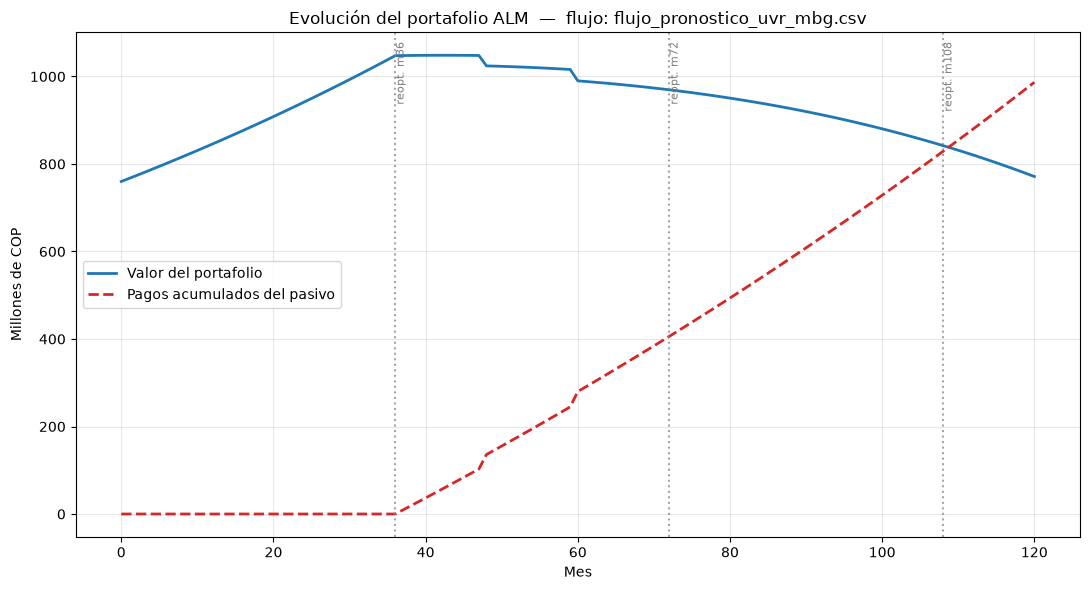

In [107]:
meses = np.arange(0, N_MESES + 1)
pago_acumulado = np.concatenate([[0.0], np.cumsum(Lt)])

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(meses, valor_portafolio / 1e6, label='Valor del portafolio', lw=2, color='#1f77b4')
ax.plot(meses, pago_acumulado / 1e6, label='Pagos acumulados del pasivo', lw=2,
        color='#d62728', ls='--')

# Líneas de reoptimización (vencimiento del bono)
for _, _, mes_fin, _ in PERIODOS[:-1]:
    ax.axvline(mes_fin, color='gray', ls=':', alpha=0.7)
    ax.text(mes_fin, ax.get_ylim()[1] * 0.98, f'  reopt. m{mes_fin}',
            rotation=90, va='top', ha='left', fontsize=8, color='gray')

ax.set_xlabel('Mes')
ax.set_ylabel('Millones de COP')
ax.set_title(f'Evolución del portafolio ALM  —  flujo: {ARCHIVO_FLUJO}')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.4 Capital residual final (mes 120)

In [108]:
residual_final = valor_portafolio[N_MESES]
total_pagado = Lt.sum()

print('=' * 55)
print('RESUMEN FINAL — ALM multiperiodo')
print('=' * 55)
print(f'Flujo del pasivo usado    : {ARCHIVO_FLUJO}')
print(f'Capital inicial C0        : {C0:,.0f} COP')
print(f'Total pagado del pasivo   : {total_pagado:,.0f} COP')
print(f'Capital residual (mes 120): {residual_final:,.0f} COP')
print(f'Crecimiento neto vs C0    : {residual_final / C0 - 1:+.2%}')
estado = 'SOLVENTE (nunca negativo)' if valor_portafolio[1:].min() >= 0 else 'INSOLVENTE en algun mes'
print(f'Estado de solvencia       : {estado}')
print(f'Valor mínimo del portafolio: {valor_portafolio[1:].min():,.0f} COP')

RESUMEN FINAL — ALM multiperiodo
Flujo del pasivo usado    : flujo_pronostico_uvr_mbg.csv
Capital inicial C0        : 760,000,000 COP
Total pagado del pasivo   : 986,738,889 COP
Capital residual (mes 120): 771,407,587 COP
Crecimiento neto vs C0    : +1.50%
Estado de solvencia       : SOLVENTE (nunca negativo)
Valor mínimo del portafolio: 766,805,835 COP


## 8. Cómo probar otros pronósticos del pasivo

Para repetir el análisis con ARIMA o SARIMAX, cambia `ARCHIVO_FLUJO` en la celda de
parámetros (sección 2) por:

- `'flujo_pronostico_uvr_arima.csv'`
- `'flujo_pronostico_uvr_Sarimax.csv'`

y vuelve a ejecutar el notebook de arriba a abajo. La función `comparar_flujos` de abajo
automatiza esa comparación.

In [109]:
def comparar_flujos(archivos):
    """Ejecuta el bucle multiperiodo para varios flujos y compara el residual final."""
    filas = []
    for arch in archivos:
        ruta = os.path.join(CARPETA_FLUJOS, arch)
        if not os.path.exists(ruta):
            print(f'  (omitido, no existe) {arch}')
            continue
        L = pd.read_csv(ruta).sort_values('periodo')['Lt'].to_numpy()
        cap = C0
        for _, mes_ini, mes_fin, activos_perm in PERIODOS:
            pesos = optimizar_periodo(activos_perm, mu_mensual, Sigma_df,
                                      SIGMA_MAX_MENSUAL, BETA_LIQUIDEZ)
            ret_m = metricas_periodo(pesos, mu_mensual, Sigma_df)['ret_mensual']
            for t in range(mes_ini, mes_fin + 1):
                cap = cap * (1 + ret_m) - L[t - 1]
        filas.append({'flujo': arch, 'total_pagado': L.sum(), 'residual_final': cap,
                      'crecimiento_vs_C0': cap / C0 - 1})
    return pd.DataFrame(filas).set_index('flujo')

comp = comparar_flujos([
    'flujo_pronostico_uvr_mbg.csv',
    'flujo_pronostico_uvr_arima.csv',
    'flujo_pronostico_uvr_Sarimax.csv',
])
display(comp.style.format({'total_pagado': '{:,.0f}', 'residual_final': '{:,.0f}',
                           'crecimiento_vs_C0': '{:+.2%}'}))

,total_pagado,residual_final,crecimiento_vs_C0
flujo,,,
flujo_pronostico_uvr_mbg.csv,"986,738,889","771,407,587",+1.50%
flujo_pronostico_uvr_arima.csv,"869,128,738","931,054,744",+22.51%
flujo_pronostico_uvr_Sarimax.csv,"926,632,896","851,543,722",+12.05%


<!-- SHORTFALL_SECCION_V1 -->
## 9. Análisis de *shortfall* y distribución del capital residual (Monte Carlo)

Hasta aquí la proyección fue **determinista**: cada mes el portafolio crecía exactamente
al retorno esperado $w^\top\mu$. Pero $\mu$ es solo el promedio; en la realidad los
retornos mensuales fluctúan. Esta sección sustituye ese retorno fijo por las **K
trayectorias de retornos mensuales simuladas** de cada activo y mide el riesgo de que el
portafolio no alcance a cubrir el pasivo.

### ¿Qué es el *shortfall*?

El **shortfall** (déficit) ocurre cuando el portafolio no tiene valor suficiente para
seguir pagando el pasivo. En términos de la recursión

$$V_t = V_{t-1}\,(1 + r_t^{(k)}) - L_t,$$

donde $r_t^{(k)} = w^\top r_t^{(k)}$ es el retorno del portafolio en el mes $t$ para la
trayectoria de mercado $k$, decimos que hubo shortfall en la trayectoria $k$ si en **algún**
mes el valor cae por debajo de cero (el portafolio se queda sin fondos para pagar).

A partir de las K trayectorias calculamos:

- **Probabilidad de shortfall**: fracción de trayectorias que se quedan sin fondos en algún
  momento de los 120 meses. Es la probabilidad de insolvencia del plan ALM.
- **Expected Shortfall (ES)** del déficit: promedio del déficit (lo que falta) en el peor
  $\alpha$ de los casos (p. ej. el 5% peor). Responde *"cuando las cosas van mal, ¿cómo de
  mal van en promedio?"*.
- **Distribución del capital residual final** $V_{120}$: media, mediana, percentiles 5 y
  95, mínimo y máximo. Nos dice el rango plausible de lo que queda al final.

### Cómo interpretarlo

- Probabilidad de shortfall baja (idealmente cerca de 0%) ⇒ el plan es robusto.
- Un $p5$ del residual final positivo y holgado ⇒ incluso en escenarios adversos queda
  capital.
- El residual determinista (sección 7) debería quedar **cerca de la media/mediana**
  simulada: si difiere mucho, la no linealidad del pasivo o la dispersión de los retornos
  está teniendo un efecto importante.


### 9.1 Carga de las K trayectorias mensuales

Cargamos las trayectorias de retornos mensuales de los tres activos. Se admite tanto el
formato `.npz` (un único archivo con arrays `Bono`, `Fondo`, `ETF`) como los CSV
individuales (`trayectorias_mensuales_<activo>.csv`, con columnas `mes_1 … mes_n`).

Cada array tiene forma `(K, n_meses)`. Usamos **las mismas K trayectorias** (el mismo
índice `k`) para los tres activos, de modo que cada simulación `k` representa una única
"realidad" de mercado coherente entre activos. Alineamos todo a `N_MESES` (= longitud de
`L_t`, 120).

In [110]:
CARPETA_ACTIVOS = "../pronosticosActivos"
ACTIVOS_TRAY = ["Bono", "Fondo", "ETF"]   # orden fijo para las columnas de la matriz


def _cargar_desde_npz(ruta):
    """Devuelve dict {activo: array (K, n_meses)} desde un .npz, o None si no sirve."""
    try:
        datos = np.load(ruta)
    except Exception as e:
        print(f"  [aviso] no se pudo leer {ruta}: {e}")
        return None
    faltan = [a for a in ACTIVOS_TRAY if a not in datos.files]
    if faltan:
        print(f"  [aviso] el .npz no contiene {faltan}; se intentará con los CSV.")
        return None
    return {a: np.asarray(datos[a], dtype=float) for a in ACTIVOS_TRAY}


def _cargar_desde_csv(carpeta):
    """Devuelve dict {activo: array (K, n_meses)} desde CSV individuales, o None."""
    salida = {}
    for a in ACTIVOS_TRAY:
        ruta = os.path.join(carpeta, f"trayectorias_mensuales_{a}.csv")
        if not os.path.exists(ruta):
            print(f"  [aviso] no existe {ruta}")
            return None
        salida[a] = pd.read_csv(ruta).to_numpy(dtype=float)
    return salida


def cargar_trayectorias(carpeta=CARPETA_ACTIVOS, n_meses=None):
    """Carga trayectorias (preferencia: .npz; respaldo: CSV) y las alinea a n_meses.

    Returns
    -------
    (R, K, n_meses) donde R es dict {activo: array (K, n_meses)}; o (None, 0, 0) si
    no se encontró ningún archivo válido.
    """
    n_meses = n_meses or N_MESES
    ruta_npz = os.path.join(carpeta, "trayectorias_mensuales.npz")

    R = None
    if os.path.exists(ruta_npz):
        R = _cargar_desde_npz(ruta_npz)
    if R is None:
        R = _cargar_desde_csv(carpeta)

    if R is None:
        print("\n*** No se encontraron trayectorias válidas (.npz ni CSV). ***")
        print("    La sección de shortfall no puede ejecutarse. Revisa la carpeta:")
        print(f"    {os.path.abspath(carpeta)}")
        return None, 0, 0

    # --- Verificación y alineación de tamaños ---
    Ks = {a: R[a].shape[0] for a in ACTIVOS_TRAY}
    if len(set(Ks.values())) != 1:
        print(f"  [aviso] los activos no tienen el mismo número de trayectorias: {Ks}")
    K = min(Ks.values())

    for a in ACTIVOS_TRAY:
        arr = R[a]
        # recortar a K trayectorias comunes
        if arr.shape[0] > K:
            arr = arr[:K]
        # alinear a n_meses (recortar o avisar si faltan meses)
        if arr.shape[1] >= n_meses:
            arr = arr[:, :n_meses]
        else:
            print(f"  [aviso] {a} tiene {arr.shape[1]} meses (<{n_meses}); se usará lo disponible.")
            n_meses = min(n_meses, arr.shape[1])
        R[a] = arr

    # re-recorte final por si n_meses cambió
    for a in ACTIVOS_TRAY:
        R[a] = R[a][:, :n_meses]

    print(f"Trayectorias cargadas: K = {K} simulaciones | {n_meses} meses | activos {ACTIVOS_TRAY}")
    return R, K, n_meses


R_tray, K_SIM, N_SIM = cargar_trayectorias()
if R_tray is not None:
    # Comprobación rápida de coherencia con mu (promedio de cada activo ~ mu_mensual)
    print("\nControl: media de las trayectorias vs mu_mensual esperado")
    for a in ACTIVOS_TRAY:
        print(f"  {a:<6}: media_sim = {R_tray[a].mean():.5f}   mu_mensual = {mu_mensual[a]:.5f}")


Trayectorias cargadas: K = 50000 simulaciones | 120 meses | activos ['Bono', 'Fondo', 'ETF']

Control: media de las trayectorias vs mu_mensual esperado
  Bono  : media_sim = 0.00672   mu_mensual = 0.00672
  Fondo : media_sim = 0.00402   mu_mensual = 0.00402
  ETF   : media_sim = 0.00896   mu_mensual = 0.00896


### 9.2 Pesos óptimos fijados (sin reoptimizar en cada trayectoria)

Reutilizamos **exactamente** los pesos `pesos_por_periodo` ya calculados en el bucle
multiperiodo (sección 6). No se reoptimiza dentro de la simulación: cada trayectoria usa el
mismo plan de inversión, respetando el esquema de 4 periodos y el cambio de pesos solo en
los **inicios de periodo** (meses 1, 37, 73, 109), coherente con el vencimiento del bono
cada 36 meses.

Construimos una matriz de pesos por mes `W` de forma `(n_meses, 3)`: la fila del mes `t`
contiene `(w_Bono, w_Fondo, w_ETF)` del periodo al que pertenece ese mes. En el periodo 4
el peso del Bono es 0 (ya venció).

In [111]:
def construir_matriz_pesos_por_mes(n_meses, periodos, pesos_por_periodo, activos):
    """Devuelve W de forma (n_meses, len(activos)) con los pesos vigentes cada mes.

    Los pesos solo cambian en los inicios de periodo (meses 1, 37, 73, 109).
    """
    W = np.zeros((n_meses, len(activos)))
    inicios = []
    for nombre, mes_ini, mes_fin, _ in periodos:
        w = np.array([pesos_por_periodo[nombre][a] for a in activos])
        # meses en base 1 -> índices base 0; recortamos a n_meses
        ini = mes_ini - 1
        fin = min(mes_fin, n_meses)       # fin inclusivo en base 1
        if ini >= n_meses:
            continue
        W[ini:fin, :] = w
        inicios.append(mes_ini)
    return W, inicios


if R_tray is not None:
    W_mes, inicios_periodo = construir_matriz_pesos_por_mes(
        N_SIM, PERIODOS, pesos_por_periodo, ACTIVOS_TRAY)

    print("Pesos vigentes por mes (cambian solo en los inicios de periodo):")
    print(f"Inicios de periodo (cambio de pesos): meses {inicios_periodo}\n")
    # Mostramos el peso del primer mes de cada periodo para verificar
    tabla_W = pd.DataFrame(
        {nombre: [pesos_por_periodo[nombre][a] for a in ACTIVOS_TRAY]
         for nombre, *_ in PERIODOS},
        index=ACTIVOS_TRAY,
    ).T
    tabla_W.index.name = "Periodo"
    display(tabla_W.style.format("{:.2%}"))


Pesos vigentes por mes (cambian solo en los inicios de periodo):
Inicios de periodo (cambio de pesos): meses [1, 37, 73, 109]



,Bono,Fondo,ETF
Periodo,,,
P1,0.00%,0.00%,100.00%
P2,0.00%,0.00%,100.00%
P3,0.00%,0.00%,100.00%
P4,0.00%,0.00%,100.00%


### 9.3 Simulación de *shortfall* mes a mes

Para cada trayectoria $k = 1, \dots, K$ y cada mes $t = 1, \dots, 120$:

1. Retorno del portafolio ese mes: $r_t^{(k)} = w_t \cdot r_t^{(k)}$, donde $w_t$ son los
   pesos del periodo correspondiente y $r_t^{(k)}$ el vector de retornos de los tres activos.
2. Recursión de valor: $V_t^{(k)} = V_{t-1}^{(k)}\,(1 + r_t^{(k)}) - L_t$, con $V_0 = C_0$.

Registramos por trayectoria:

- **Hubo shortfall**: `True` si en algún mes $V_t^{(k)} < 0$.
- **Déficit máximo**: la peor caída por debajo de cero, es decir
  $\max_t\, \max(0,\, -V_t^{(k)})$ (0 si nunca fue negativo).
- **Capital residual final** $V_{120}^{(k)}$.

El cálculo está **vectorizado** sobre las K trayectorias para que sea rápido.

In [112]:
def simular_shortfall(R, W, Lt, C0, n_meses):
    """Simulación vectorizada de la recursión V_t = V_{t-1}(1+r_t) - L_t.

    Parameters
    ----------
    R        : dict {activo: (K, n_meses)} retornos mensuales simulados
    W        : (n_meses, 3) pesos vigentes cada mes (orden ACTIVOS_TRAY)
    Lt       : (n_meses,) pasivo mensual
    C0       : capital inicial
    n_meses  : horizonte

    Returns
    -------
    dict con:
      V            : (K, n_meses+1) valor del portafolio (col 0 = C0)
      hubo_short   : (K,) bool, True si V_t<0 en algún mes
      deficit_max  : (K,) float, mayor déficit (>=0) por trayectoria
      residual     : (K,) float, V_120 de cada trayectoria
      ret_port     : (K, n_meses) retorno mensual del portafolio
    """
    # Apilamos retornos en un tensor (K, n_meses, 3) en el orden ACTIVOS_TRAY
    K = R[ACTIVOS_TRAY[0]].shape[0]
    Rstack = np.stack([R[a] for a in ACTIVOS_TRAY], axis=2)   # (K, n_meses, 3)

    # Retorno del portafolio por mes: suma_a W[t,a] * r_{k,t,a}  -> (K, n_meses)
    # W tiene forma (n_meses, 3); broadcasting sobre K.
    ret_port = np.einsum("kta,ta->kt", Rstack, W)

    V = np.empty((K, n_meses + 1))
    V[:, 0] = C0
    for t in range(1, n_meses + 1):
        V[:, t] = V[:, t - 1] * (1.0 + ret_port[:, t - 1]) - Lt[t - 1]

    V_meses = V[:, 1:]                       # (K, n_meses), sin la columna inicial
    hubo_short = (V_meses < 0).any(axis=1)
    deficit_max = np.maximum(0.0, -V_meses).max(axis=1)
    residual = V[:, n_meses]

    return {
        "V": V,
        "hubo_short": hubo_short,
        "deficit_max": deficit_max,
        "residual": residual,
        "ret_port": ret_port,
    }


if R_tray is not None:
    sim = simular_shortfall(R_tray, W_mes, Lt[:N_SIM], C0, N_SIM)
    print(f"Simulación completada sobre {K_SIM} trayectorias y {N_SIM} meses.")
    print(f"Trayectorias con shortfall: {int(sim['hubo_short'].sum())} de {K_SIM}")


Simulación completada sobre 50000 trayectorias y 120 meses.
Trayectorias con shortfall: 0 de 50000


### 9.4 Métricas de riesgo

- **Probabilidad de shortfall** $= \#\{k : \text{hubo shortfall}\} / K$.
- **Expected Shortfall (ES) del déficit** al nivel $\alpha$: promedio del déficit en el
  peor $\alpha$ de las trayectorias (usamos el déficit máximo de cada trayectoria y
  promediamos la cola superior $\alpha$). Si ninguna trayectoria tiene déficit, el ES es 0.
- **Distribución del capital residual final**: media, mediana, p5, p95, mínimo y máximo.

In [113]:
def expected_shortfall_deficit(deficit_max, alpha=0.05):
    """ES del déficit: media del peor alpha de los déficits (cola superior)."""
    if deficit_max.size == 0:
        return 0.0
    k = max(1, int(np.ceil(alpha * deficit_max.size)))
    peores = np.sort(deficit_max)[::-1][:k]   # los k déficits más grandes
    return float(peores.mean())


def resumen_residual(residual):
    return {
        "media":   float(np.mean(residual)),
        "mediana": float(np.median(residual)),
        "p5":      float(np.percentile(residual, 5)),
        "p95":     float(np.percentile(residual, 95)),
        "minimo":  float(np.min(residual)),
        "maximo":  float(np.max(residual)),
    }


if R_tray is not None:
    ALPHA = 0.05
    prob_short = float(sim["hubo_short"].mean())
    es_deficit = expected_shortfall_deficit(sim["deficit_max"], alpha=ALPHA)
    res_stats = resumen_residual(sim["residual"])

    print("=" * 60)
    print(f"MÉTRICAS DE RIESGO — flujo: {ARCHIVO_FLUJO}  |  K = {K_SIM}")
    print("=" * 60)
    print(f"Probabilidad de shortfall        : {prob_short:.2%}")
    print(f"Expected Shortfall (deficit, {ALPHA:.0%}) : {es_deficit:,.0f} COP")
    print("-" * 60)
    print("Distribución del capital residual final V_120:")
    print(f"  Media   : {res_stats['media']:,.0f} COP")
    print(f"  Mediana : {res_stats['mediana']:,.0f} COP")
    print(f"  p5      : {res_stats['p5']:,.0f} COP")
    print(f"  p95     : {res_stats['p95']:,.0f} COP")
    print(f"  Mínimo  : {res_stats['minimo']:,.0f} COP")
    print(f"  Máximo  : {res_stats['maximo']:,.0f} COP")

    tabla_residual = pd.DataFrame([res_stats]).T.rename(columns={0: "COP"})
    tabla_residual.index.name = "estadístico"
    display(tabla_residual.style.format("{:,.0f}"))


MÉTRICAS DE RIESGO — flujo: flujo_pronostico_uvr_mbg.csv  |  K = 50000
Probabilidad de shortfall        : 0.00%
Expected Shortfall (deficit, 5%) : 0 COP
------------------------------------------------------------
Distribución del capital residual final V_120:
  Media   : 784,267,787 COP
  Mediana : 770,499,547 COP
  p5      : 495,467,494 COP
  p95     : 1,122,162,150 COP
  Mínimo  : 363,523,767 COP
  Máximo  : 1,338,904,569 COP


,COP
estadístico,
media,"784,267,787"
mediana,"770,499,547"
p5,"495,467,494"
p95,"1,122,162,150"
minimo,"363,523,767"
maximo,"1,338,904,569"


### 9.5 Histograma del capital residual final

La distribución de $V_{120}$ a lo largo de las K trayectorias. Marcamos la mediana, el p5 y
el residual **determinista** de la sección 7 para comparar visualmente.

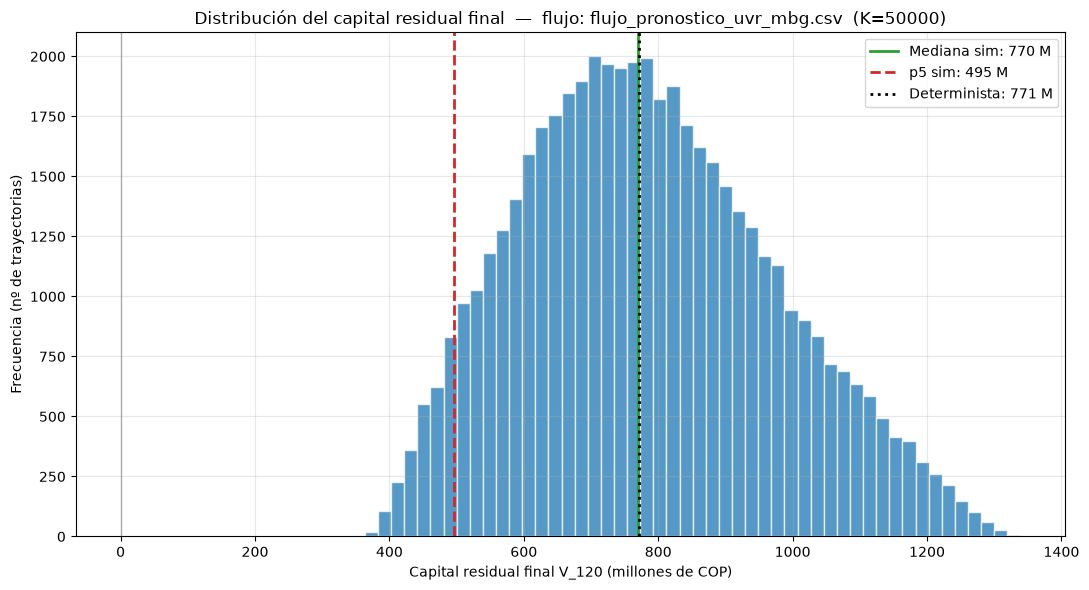

In [114]:
if R_tray is not None:
    residual_determinista = float(valor_portafolio[N_MESES])   # de la sección 6/7

    fig, ax = plt.subplots(figsize=(11, 6))
    ax.hist(sim["residual"] / 1e6, bins=50, color="#1f77b4", alpha=0.75,
            edgecolor="white")

    ax.axvline(res_stats["mediana"] / 1e6, color="#2ca02c", lw=2,
               label=f"Mediana sim: {res_stats['mediana']/1e6:,.0f} M")
    ax.axvline(res_stats["p5"] / 1e6, color="#d62728", lw=2, ls="--",
               label=f"p5 sim: {res_stats['p5']/1e6:,.0f} M")
    ax.axvline(residual_determinista / 1e6, color="black", lw=2, ls=":",
               label=f"Determinista: {residual_determinista/1e6:,.0f} M")
    ax.axvline(0, color="gray", lw=1, alpha=0.6)

    ax.set_xlabel("Capital residual final V_120 (millones de COP)")
    ax.set_ylabel("Frecuencia (nº de trayectorias)")
    ax.set_title(f"Distribución del capital residual final  —  flujo: {ARCHIVO_FLUJO}  (K={K_SIM})")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


### 9.6 (Opcional) Evolución de los percentiles del valor del portafolio

Bandas de incertidumbre a lo largo de los 120 meses: percentil 5 (escenario adverso),
mediana (percentil 50) y percentil 95 (escenario favorable). La línea de pagos acumulados
y el eje en cero ayudan a ver cuándo y con qué probabilidad el plan se acerca al shortfall.

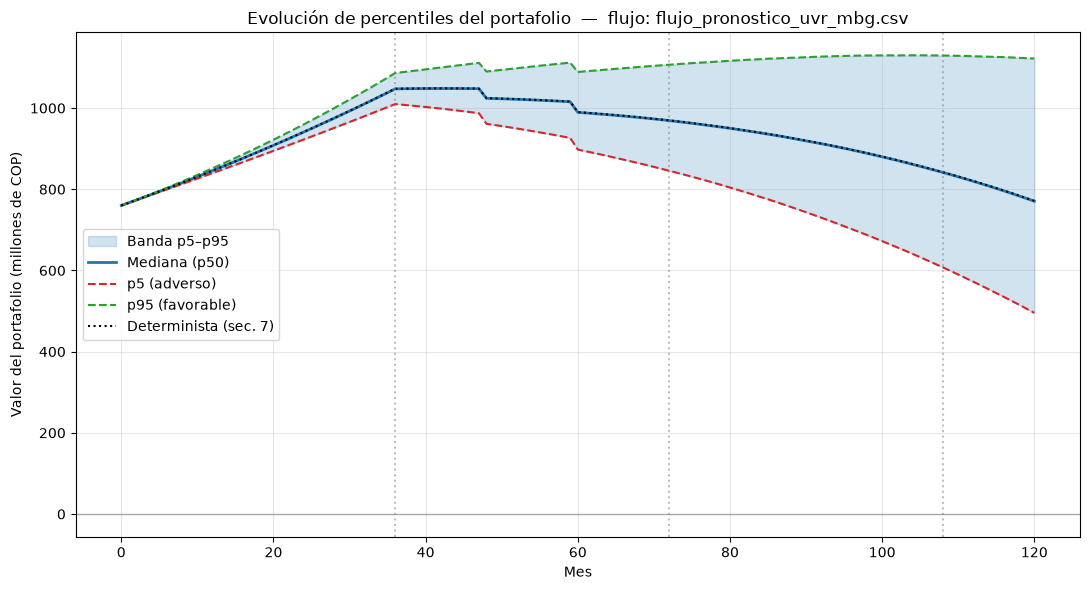

In [115]:
if R_tray is not None:
    V = sim["V"]                      # (K, n_meses+1)
    meses_sim = np.arange(0, N_SIM + 1)

    p05 = np.percentile(V, 5,  axis=0)
    p50 = np.percentile(V, 50, axis=0)
    p95 = np.percentile(V, 95, axis=0)

    fig, ax = plt.subplots(figsize=(11, 6))
    ax.fill_between(meses_sim, p05 / 1e6, p95 / 1e6, color="#1f77b4", alpha=0.20,
                    label="Banda p5–p95")
    ax.plot(meses_sim, p50 / 1e6, color="#1f77b4", lw=2, label="Mediana (p50)")
    ax.plot(meses_sim, p05 / 1e6, color="#d62728", lw=1.5, ls="--", label="p5 (adverso)")
    ax.plot(meses_sim, p95 / 1e6, color="#2ca02c", lw=1.5, ls="--", label="p95 (favorable)")

    # Proyección determinista de la sección 6 para comparar
    ax.plot(np.arange(0, N_MESES + 1), valor_portafolio / 1e6, color="black", lw=1.5,
            ls=":", label="Determinista (sec. 7)")
    ax.axhline(0, color="gray", lw=1, alpha=0.6)

    for mi in inicios_periodo[1:]:
        ax.axvline(mi - 1, color="gray", ls=":", alpha=0.5)

    ax.set_xlabel("Mes")
    ax.set_ylabel("Valor del portafolio (millones de COP)")
    ax.set_title(f"Evolución de percentiles del portafolio  —  flujo: {ARCHIVO_FLUJO}")
    ax.legend(loc="best")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


### 9.7 Comparación: determinista vs simulado

Ponemos lado a lado el residual **determinista** (sección 7, calculado con $\mu$) frente a
las estadísticas del residual **simulado**. Si el determinista queda cerca de la
media/mediana y el p5 es positivo, el plan es robusto ante la incertidumbre de mercado.

In [116]:
if R_tray is not None:
    comparacion = pd.DataFrame({
        "valor_COP": {
            "Residual DETERMINISTA (sec. 7)": residual_determinista,
            "Residual simulado — media":      res_stats["media"],
            "Residual simulado — mediana":    res_stats["mediana"],
            "Residual simulado — p5":         res_stats["p5"],
            "Residual simulado — p95":        res_stats["p95"],
        }
    })
    comparacion["vs C0"] = comparacion["valor_COP"] / C0 - 1
    display(comparacion.style.format({"valor_COP": "{:,.0f}", "vs C0": "{:+.2%}"}))

    dif_med = residual_determinista - res_stats["media"]
    print(f"\nDeterminista - media simulada: {dif_med:,.0f} COP "
          f"({dif_med / residual_determinista:+.2%} del determinista)")
    print(f"Probabilidad de shortfall: {prob_short:.2%}")
    if prob_short == 0:
        print("=> Ninguna trayectoria agota el capital: plan robusto bajo este flujo.")
    else:
        print("=> Hay trayectorias que agotan el capital: revisar riesgo/pesos/flujo.")


,valor_COP,vs C0
Residual DETERMINISTA (sec. 7),"771,407,587",+1.50%
Residual simulado — media,"784,267,787",+3.19%
Residual simulado — mediana,"770,499,547",+1.38%
Residual simulado — p5,"495,467,494",-34.81%
Residual simulado — p95,"1,122,162,150",+47.65%



Determinista - media simulada: -12,860,200 COP (-1.67% del determinista)
Probabilidad de shortfall: 0.00%
=> Ninguna trayectoria agota el capital: plan robusto bajo este flujo.


### 9.8 Shortfall para los tres pronósticos del pasivo (MBG / ARIMA / SARIMAX)

Repetimos el análisis de shortfall para los tres flujos usando **las mismas trayectorias y
los mismos pesos óptimos**. Solo cambia la serie $L_t$ del pasivo. Así se ve qué pronóstico
del pasivo es más exigente para el plan de inversión. Si algún archivo de flujo no existe,
se avisa y se omite sin romper la ejecución.

In [117]:
def shortfall_por_flujo(archivos, R, W, C0, n_meses, alpha=0.05):
    """Corre la simulación de shortfall para varios flujos del pasivo."""
    if R is None:
        print("No hay trayectorias cargadas: no se puede ejecutar el comparativo.")
        return pd.DataFrame()

    filas = []
    for arch in archivos:
        ruta = os.path.join(CARPETA_FLUJOS, arch)
        if not os.path.exists(ruta):
            print(f"  [aviso] no existe el flujo {arch}; se omite.")
            continue
        L = pd.read_csv(ruta).sort_values("periodo")["Lt"].to_numpy()
        if len(L) < n_meses:
            print(f"  [aviso] {arch} tiene {len(L)} meses (<{n_meses}); se omite.")
            continue
        s = simular_shortfall(R, W, L[:n_meses], C0, n_meses)
        rs = resumen_residual(s["residual"])
        filas.append({
            "flujo": arch,
            "prob_shortfall": float(s["hubo_short"].mean()),
            "ES_deficit_5pct": expected_shortfall_deficit(s["deficit_max"], alpha),
            "residual_media": rs["media"],
            "residual_mediana": rs["mediana"],
            "residual_p5": rs["p5"],
            "residual_p95": rs["p95"],
        })
    return pd.DataFrame(filas).set_index("flujo") if filas else pd.DataFrame()


if R_tray is not None:
    comp_short = shortfall_por_flujo(
        ["flujo_pronostico_uvr_mbg.csv",
         "flujo_pronostico_uvr_arima.csv",
         "flujo_pronostico_uvr_Sarimax.csv"],
        R_tray, W_mes, C0, N_SIM, alpha=0.05,
    )
    if not comp_short.empty:
        display(comp_short.style.format({
            "prob_shortfall": "{:.2%}",
            "ES_deficit_5pct": "{:,.0f}",
            "residual_media": "{:,.0f}",
            "residual_mediana": "{:,.0f}",
            "residual_p5": "{:,.0f}",
            "residual_p95": "{:,.0f}",
        }))


,prob_shortfall,ES_deficit_5pct,residual_media,residual_mediana,residual_p5,residual_p95
flujo,,,,,,
flujo_pronostico_uvr_mbg.csv,0.00%,0,"784,267,787","770,499,547","495,467,494","1,122,162,150"
flujo_pronostico_uvr_arima.csv,0.00%,0,"944,228,737","929,886,205","642,928,287","1,295,579,786"
flujo_pronostico_uvr_Sarimax.csv,0.00%,0,"864,549,194","850,540,053","569,873,808","1,208,836,918"
